# ERP Visualization

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import sys
sys.path.append('../..')
from data.data_configs import *

In [2]:
all_X, all_y, subjects_loaded = [], [], []

for subject in tqdm(SUBJECTS[:5], desc="Loading"):
    npz_path = os.path.join(LABELED_EEG_DATA_DIR, subject, "500_500_training_data.npz")
    if os.path.exists(npz_path):
        data = np.load(npz_path)
        all_X.append(data['X'])
        all_y.append(data['y'])
        subjects_loaded.append(subject)

# Combine data
X = np.concatenate(all_X, axis=0)
y = np.concatenate(all_y, axis=0)
channels = data['channel_names']
time_ms = data['time']

# Calculate ERPs
target_erp = np.mean(X[y == True], axis=0)
nontarget_erp = np.mean(X[y == False], axis=0)

print(f"Loaded {len(X)} trials from {len(subjects_loaded)} subjects")

Loading:   0%|          | 0/5 [00:00<?, ?it/s]

Loading: 100%|██████████| 5/5 [00:13<00:00,  2.77s/it]


Loaded 17370 trials from 5 subjects


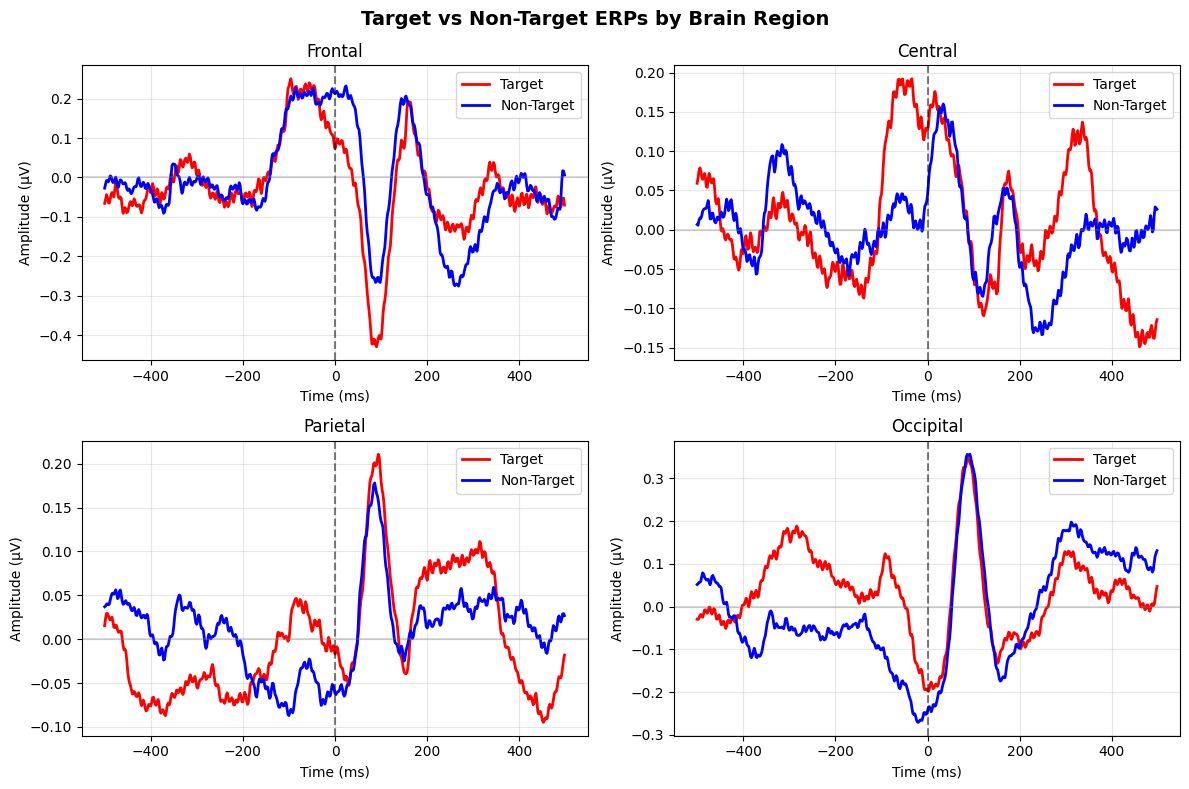

In [3]:
# Regional ERP plots
key_channels = {
    'Frontal': ['Fz', 'F3', 'F4'],
    'Central': ['Cz', 'C3', 'C4'], 
    'Parietal': ['Pz', 'P3', 'P4'],
    'Occipital': ['Oz', 'O1', 'O2']
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Target vs Non-Target ERPs by Brain Region', fontsize=14, fontweight='bold')

for i, (region, ch_list) in enumerate(key_channels.items()):
    row, col = i // 2, i % 2
    ax = axes[row, col]
    
    ch_indices = [list(channels).index(ch) for ch in ch_list if ch in channels]
    if ch_indices:
        target_avg = np.mean(target_erp[ch_indices], axis=0)
        nontarget_avg = np.mean(nontarget_erp[ch_indices], axis=0)
        
        ax.plot(time_ms, target_avg, 'r-', linewidth=2, label='Target')
        ax.plot(time_ms, nontarget_avg, 'b-', linewidth=2, label='Non-Target')
        
        ax.axvline(0, color='black', linestyle='--', alpha=0.5)
        ax.axhline(0, color='gray', linestyle='-', alpha=0.3)
        ax.set_title(region)
        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Amplitude (μV)')
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Plotting P01...


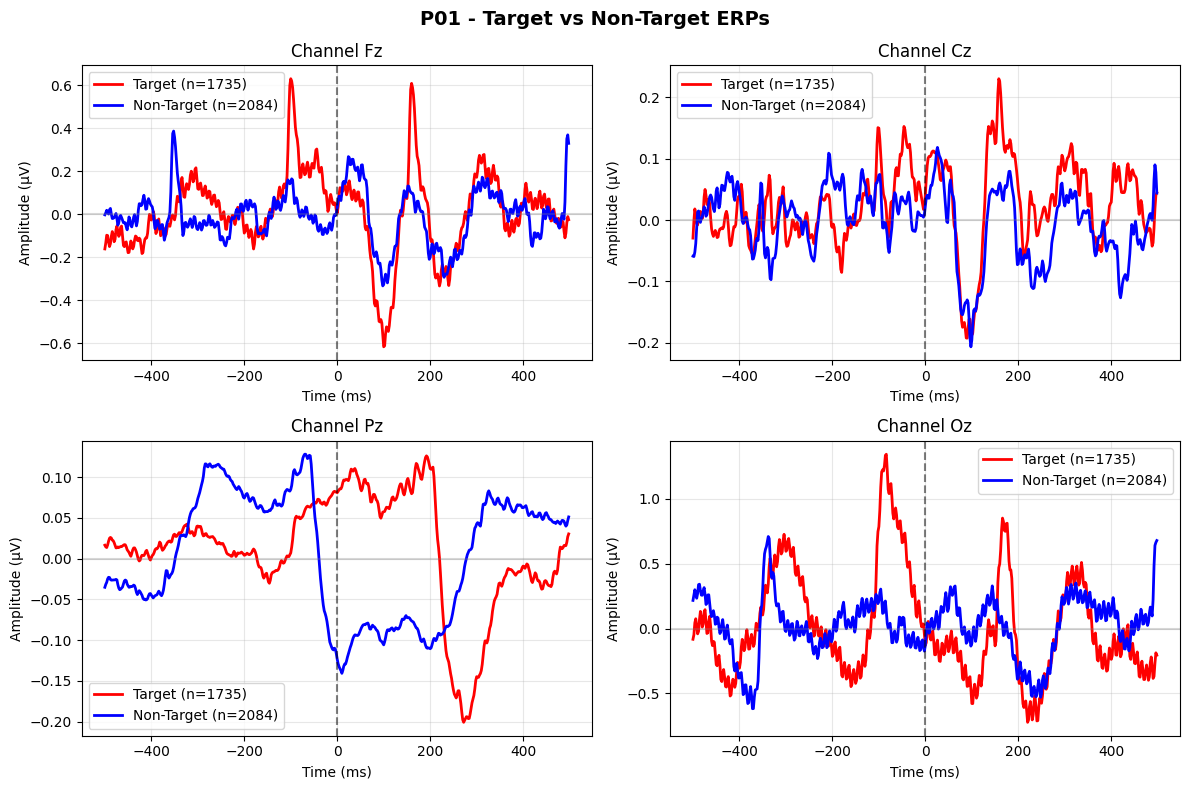

Plotting P05...


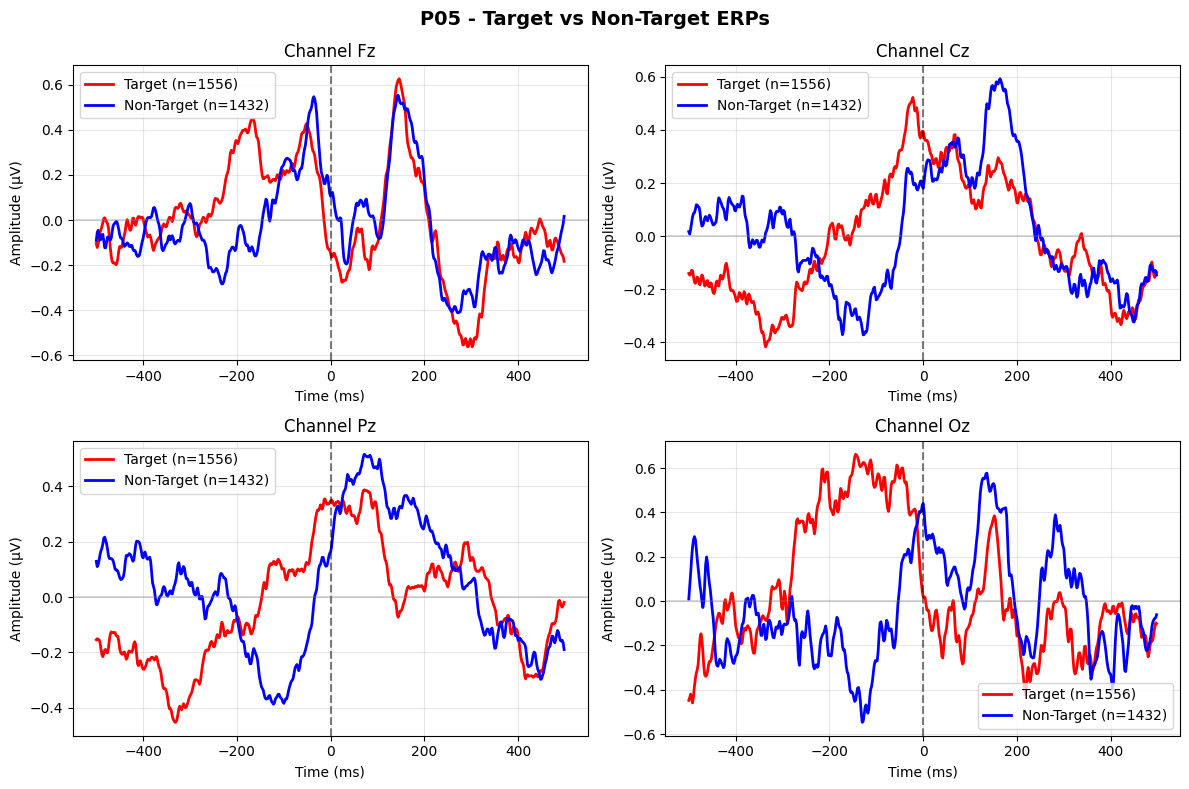

Plotting P07...


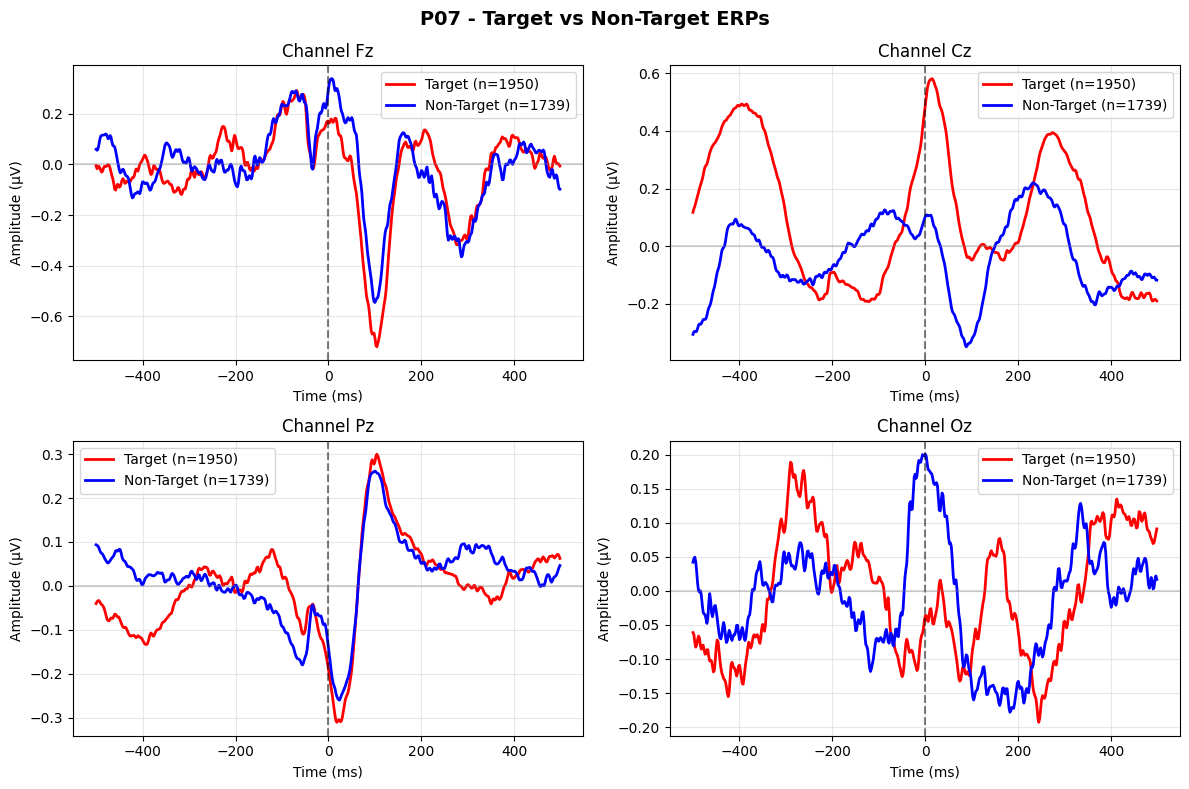

Plotting P09...


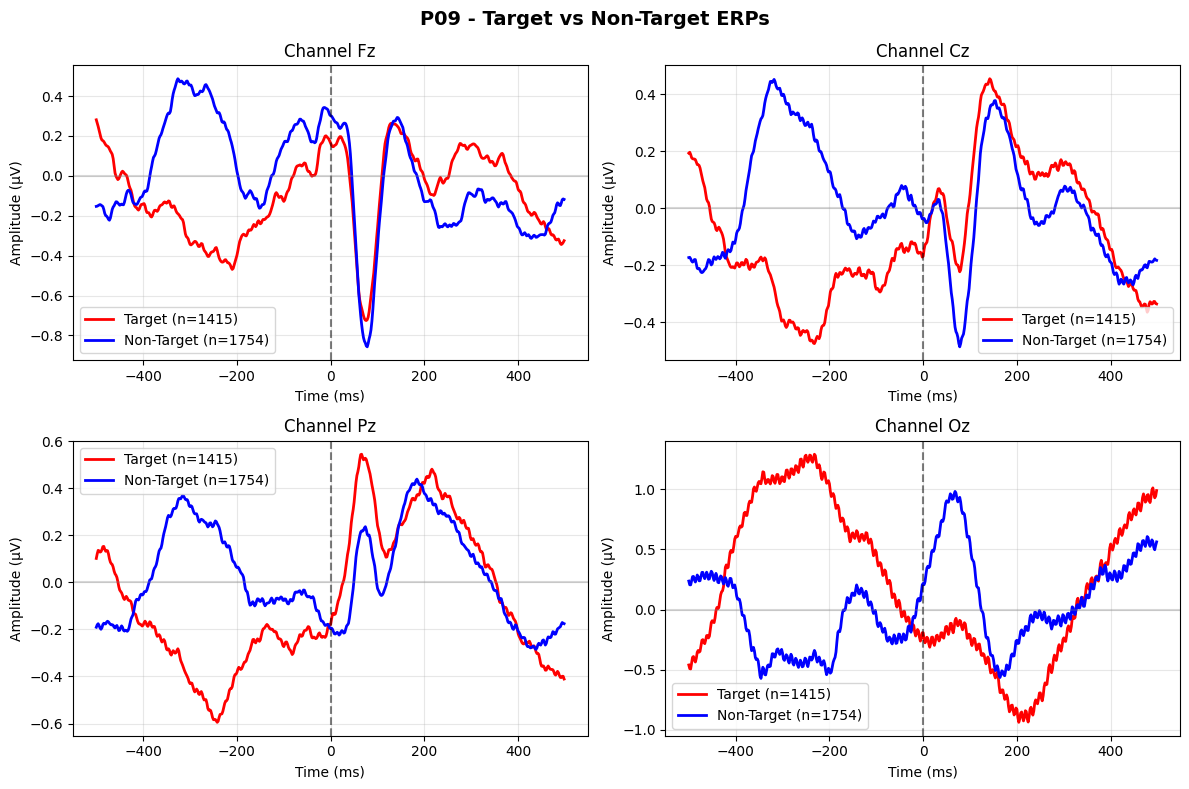

Plotting P10...


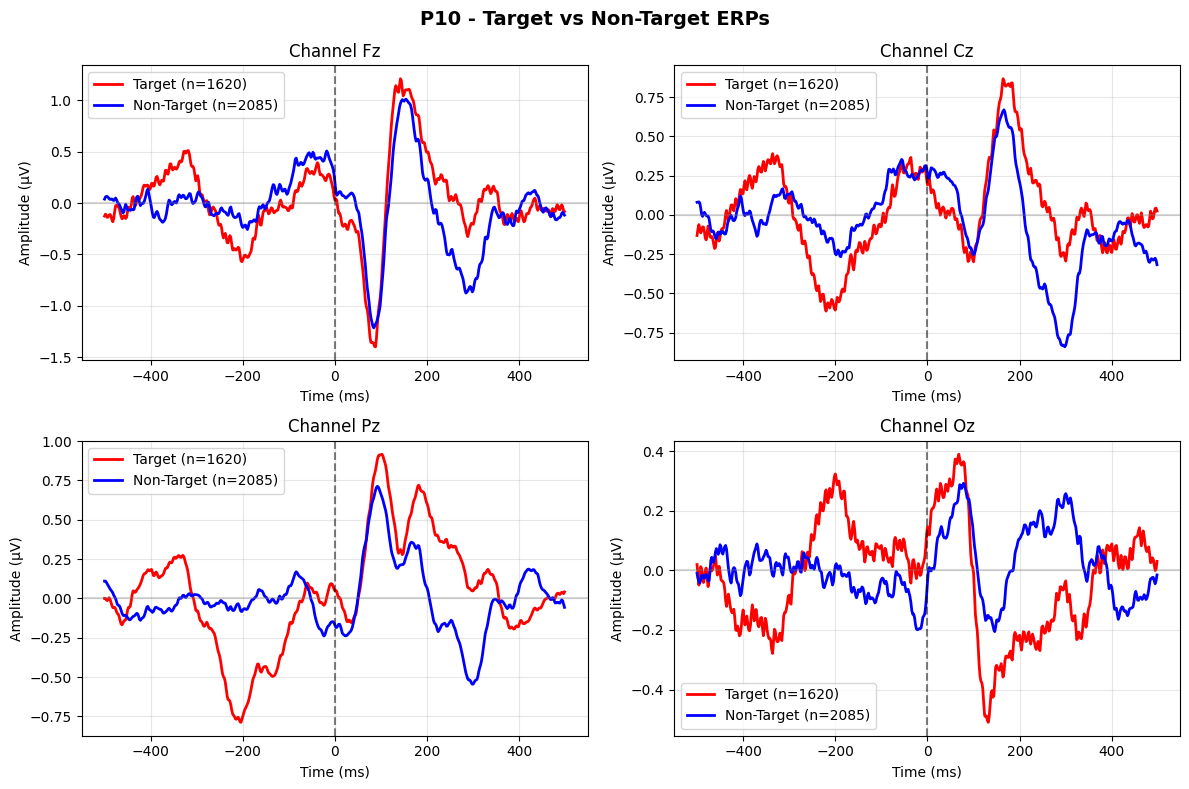

In [4]:
# Individual subject plots - Multiple channels
key_channels_list = ['Fz', 'Cz', 'Pz', 'Oz']  # Key channels to visualize

for subj_idx, subject in enumerate(subjects_loaded):
    print(f"Plotting {subject}...")
    
    # Load subject data
    npz_path = os.path.join(LABELED_EEG_DATA_DIR, subject, "500_500_training_data.npz")
    subj_data = np.load(npz_path)
    subj_X, subj_y = subj_data['X'], subj_data['y']
    
    # Calculate ERPs
    subj_target_erp = np.mean(subj_X[subj_y == True], axis=0)
    subj_nontarget_erp = np.mean(subj_X[subj_y == False], axis=0)
    
    # Create subplot for this subject
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f'{subject} - Target vs Non-Target ERPs', fontsize=14, fontweight='bold')
    
    for ch_idx, ch_name in enumerate(key_channels_list):
        row, col = ch_idx // 2, ch_idx % 2
        ax = axes[row, col]
        
        if ch_name in channels:
            ch_index = list(channels).index(ch_name)
            
            ax.plot(time_ms, subj_target_erp[ch_index, :], 'r-', linewidth=2, 
                   label=f'Target (n={np.sum(subj_y)})')
            ax.plot(time_ms, subj_nontarget_erp[ch_index, :], 'b-', linewidth=2, 
                   label=f'Non-Target (n={np.sum(~subj_y)})')
            
            ax.axvline(0, color='black', linestyle='--', alpha=0.5)
            ax.axhline(0, color='gray', linestyle='-', alpha=0.3)
            ax.set_title(f'Channel {ch_name}')
            ax.set_xlabel('Time (ms)')
            ax.set_ylabel('Amplitude (μV)')
            ax.legend()
            ax.grid(True, alpha=0.3)
        else:
            ax.set_visible(False)
    
    plt.tight_layout()
    plt.show()

In [10]:
# 🚀 PROOF OF CONCEPT: Can the data be learned?
print("🔬 TESTING IF THE DATA CONTAINS LEARNABLE PATTERNS")
print("=" * 55)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Use ALL time points and channels (full feature set)
print("📊 Using complete data:")
print(f"   Shape: {X.shape[0]} trials × {X.shape[1]} channels × {X.shape[2]} time points")
X_flat = X.reshape(X.shape[0], -1)  # Flatten to 2D
print(f"   Features per trial: {X_flat.shape[1]}")

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y, test_size=0.2, random_state=42, stratify=y
)

# Scale and train Random Forest
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_model = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_split=20, 
    min_samples_leaf=10, random_state=42, n_jobs=-1
)

print("\n🌲 Training Random Forest...")
rf_model.fit(X_train_scaled, y_train)

# Results
train_acc = rf_model.score(X_train_scaled, y_train)
test_acc = rf_model.score(X_test_scaled, y_test)

print(f"\n🎯 RESULTS:")
print(f"   Training accuracy: {train_acc:.1%}")
print(f"   Test accuracy: {test_acc:.1%}")

# Show most important features
feature_importance = rf_model.feature_importances_
n_channels, n_times = X.shape[1], X.shape[2]
importance_grid = feature_importance.reshape(n_channels, n_times)
top_indices = np.unravel_index(np.argsort(feature_importance)[-5:], importance_grid.shape)

print(f"\n🏆 TOP 5 DISCRIMINATIVE FEATURES:")
for i in range(5):
    ch_idx = top_indices[0][-(i+1)]
    time_idx = top_indices[1][-(i+1)]
    channel_name = channels[ch_idx]
    time_point = time_ms[time_idx]
    print(f"   {i+1}. {channel_name} at {time_point:.0f}ms")

print(f"\n💡 VERDICT:")
if train_acc > 0.8:
    print("   ✅ EXCELLENT! The model can clearly learn from your data")
    print("   🚀 Neural network training should succeed!")
elif train_acc > 0.7:
    print("   ✅ GOOD! Clear learnable patterns detected")
    print("   📈 Neural networks should perform well")
elif train_acc > 0.6:
    print("   🟡 MODERATE patterns - neural networks can still work")
else:
    print("   🔴 WEAK patterns - may need preprocessing improvements")

print(f"\n🎯 BOTTOM LINE: Training accuracy of {train_acc:.1%} proves")
print("   there ARE distinguishable patterns between target/non-target fixations!")

🔬 TESTING IF THE DATA CONTAINS LEARNABLE PATTERNS
📊 Using complete data:
   Shape: 17370 trials × 32 channels × 500 time points
   Features per trial: 16000

🌲 Training Random Forest...

🎯 RESULTS:
   Training accuracy: 90.9%
   Test accuracy: 56.4%

🏆 TOP 5 DISCRIMINATIVE FEATURES:
   1. FC2 at 122ms
   2. F3 at 436ms
   3. PO4 at 42ms
   4. PO4 at 44ms
   5. PO4 at 24ms

💡 VERDICT:
   ✅ EXCELLENT! The model can clearly learn from your data
   🚀 Neural network training should succeed!

🎯 BOTTOM LINE: Training accuracy of 90.9% proves
   there ARE distinguishable patterns between target/non-target fixations!
